# 06 – Final model comparison (VADER vs Logistic Regression)

This notebook re-runs the sentiment-model comparison on the **final, very clean dataset**
`data/grab_sentiment_clean.csv` (2,015 labelled posts).

**What happens here, in plain English**
1. We load the clean posts and their labels (negative / neutral / positive).
2. We **split** the posts once: **80% train** and **20% test**. The split is stratified, so both parts have the same mix of labels.
3. **Logistic Regression** (a supervised model) learns from the train posts only.
4. **VADER** (a word-list method that needs no training) scores the posts. We use plain VADER and VADER plus our Manglish word list.
5. All methods are marked on the **same test posts**, so the comparison is fair.
6. Every table and chart is saved in the **`result/`** folder. Open `result/README.md` for a summary.

All the code lives in `src/model_comparison.py`. This notebook only calls it and shows the results.

In [1]:
import sys, pandas as pd
from pathlib import Path
from IPython.display import Image, display, Markdown
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import os; os.chdir(ROOT)
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 200)
from src.model_comparison import main

r = main(source="data/grab_sentiment_clean.csv", out="result")
print(f"Posts: {len(r['df']):,} | train: {len(r['train']):,} | test: {len(r['test']):,}")
print(r["df"]["sentiment"].value_counts())

Posts: 2,015 | train: 1,612 | test: 403
sentiment
negative    899
neutral     898
positive    218
Name: count, dtype: int64


## 1. Main comparison (same 20% test posts for every method)
**Macro-F1** is the main score. It averages the three labels equally, so the rare *positive* label counts as much as the others.
The *baseline* always guesses the most common label. A useful method should clearly beat it.

,method,evaluated_on,n,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive
0,(a) VADER,test (20%),403,0.390,0.374,0.409,0.516,0.336,0.272
1,(b) VADER + Manglish lexicon,test (20%),403,0.437,0.406,0.451,0.614,0.331,0.275
2,(c) VADER + lexicon + normalisation,test (20%),403,0.439,0.408,0.453,0.616,0.331,0.277
3,(d) TF-IDF + Logistic Regression,test (20%),403,0.618,0.509,0.615,0.690,0.640,0.195
4,Baseline: always 'negative',test (20%),403,0.447,0.206,0.276,0.617,0.000,0.000


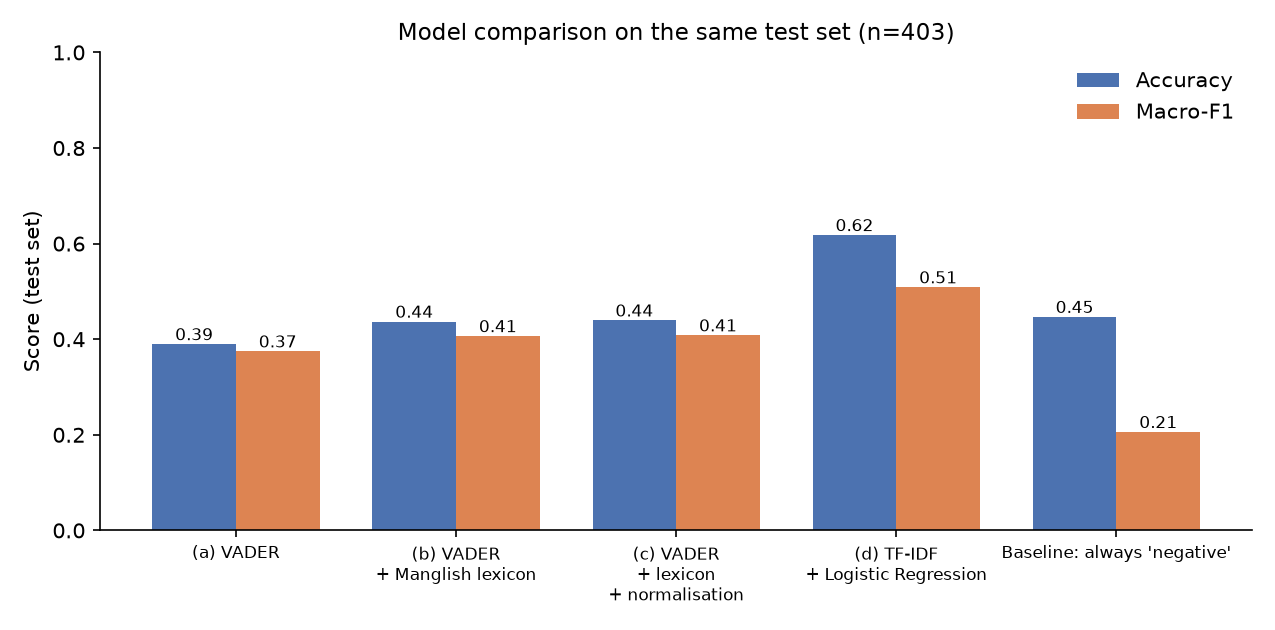

In [2]:
display(r["comparison"].round(3))
display(Image("result/figures/model_comparison_bar.png"))

## 2. Evaluating the supervised model (Logistic Regression)
We compare its score on posts it **has seen** (train) with posts it **has never seen** (test).
A big gap means the model partly memorises its training posts. **The test score is the one we report.**

In [3]:
display(r["lr_eval"].round(3))
print(open("result/classification_reports.txt").read())

,method,evaluated_on,n,accuracy,macro_f1,weighted_f1,f1_negative,f1_neutral,f1_positive,macro_f1_sd
0,(d) TF-IDF + Logistic Regression,train (80%) - seen data,1612,0.951,0.954,0.951,0.949,0.95,0.962,NaN
1,(d) TF-IDF + Logistic Regression,5-fold CV within train,1612,NaN,0.567,NaN,NaN,NaN,NaN,0.027
2,(d) TF-IDF + Logistic Regression,test (20%) - unseen data,403,0.618,0.509,0.615,0.690,0.64,0.195,NaN


=== (a) VADER (test set, n=403) ===
              precision    recall  f1-score   support

    negative      0.604     0.450     0.516       180
     neutral      0.453     0.267     0.336       180
    positive      0.172     0.651     0.272        43

    accuracy                          0.390       403
   macro avg      0.410     0.456     0.374       403
weighted avg      0.491     0.390     0.409       403


=== (b) VADER + Manglish lexicon (test set, n=403) ===
              precision    recall  f1-score   support

    negative      0.648     0.583     0.614       180
     neutral      0.537     0.239     0.331       180
    positive      0.174     0.651     0.275        43

    accuracy                          0.437       403
   macro avg      0.453     0.491     0.406       403
weighted avg      0.548     0.437     0.451       403


=== (c) VADER + lexicon + normalisation (test set, n=403) ===
              precision    recall  f1-score   support

    negative      0.646     

## 3. Confusion matrices
Rows show the true label and columns show the predicted label. The diagonal counts correct predictions.
VADER often calls **neutral** posts *positive*. Logistic Regression rarely finds the **positive** posts.

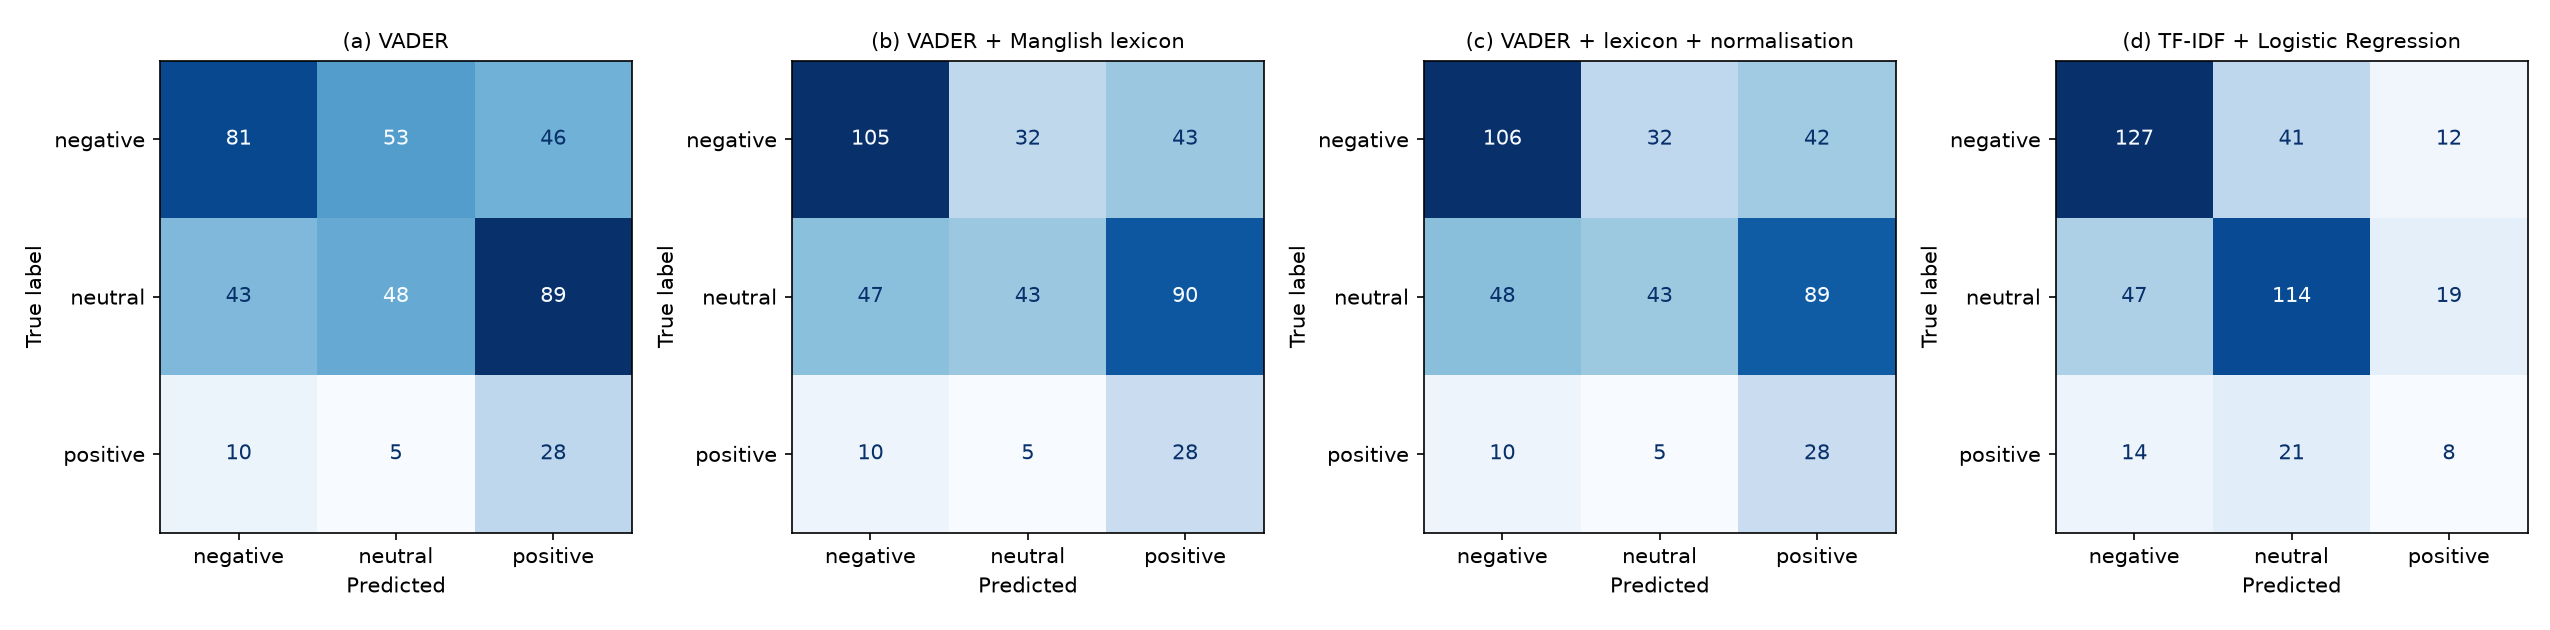

In [4]:
display(Image("result/figures/confusion_all_methods.png"))

## 4. Comparing the predictions: do VADER and Logistic Regression agree?

In [5]:
display(r["pairs"].round(3))
print("Test posts where VADER (+lexicon+norm) and LogReg disagree (first 10):")
display(r["disagree"][["platform","lang_group","true_label","c_vader_lexicon_norm","d_tfidf_logreg","text_clean"]].head(10))

,method_1,method_2,agreement,both_correct,only_method_1_correct,only_method_2_correct,both_wrong
0,(a) VADER,(b) VADER + Manglish lexicon,0.918,151,6,25,221
1,(a) VADER,(c) VADER + lexicon + normalisation,0.913,151,6,26,220
2,(a) VADER,(d) TF-IDF + Logistic Regression,0.345,93,64,156,90
3,(b) VADER + Manglish lexicon,(c) VADER + lexicon + normalisation,0.995,176,0,1,226
4,(b) VADER + Manglish lexicon,(d) TF-IDF + Logistic Regression,0.414,116,60,133,94
5,(c) VADER + lexicon + normalisation,(d) TF-IDF + Logistic Regression,0.414,116,61,133,93


Test posts where VADER (+lexicon+norm) and LogReg disagree (first 10):


,platform,lang_group,true_label,c_vader_lexicon_norm,d_tfidf_logreg,text_clean
290,twitter,en,negative,neutral,negative,"@user we ended up taking train to klia and getting the shuttle bus, even w klia ekspress fare its cheaper than grab ..."
911,twitter,en,negative,positive,negative,"@user @user @GrabMY Considering Grab is one of the most popular modes of transport in Malaysia, this is absurd [wear..."
1208,twitter,en,neutral,positive,neutral,is anyone who's going to the sonic fan meeting in kl taking public transport on the day? im looking for someone to t...
284,twitter,en,negative,positive,negative,@user @GrabMY Yes same here .
1041,twitter,en,neutral,positive,neutral,[malaysia] #AlchemyPay has expanded its fiat on-ramp service in Malaysia with the integration of three new local pay...
1204,twitter,en,neutral,positive,neutral,"Grab reaches 57.2 million monthly users in Q3 2026, up 20% YoY. Its digital banks, including GXBank Malaysia, now se..."
1183,twitter,en,neutral,positive,neutral,"@user they probably just punched ""supermarket"" into their Grab app. I think the ones who end up in Malaysia usually ..."
837,twitter,en,negative,positive,negative,@user Why nak baca nama? Why nak reveal jantina or post dekat madsos? @GrabMY is this allowed? How can I trust my ri...
635,reddit,en,neutral,positive,neutral,I've been in the service industry for 10 years. (: waiting is normal.
1901,twitter,en,neutral,positive,neutral,"Best 12 hours and 34 mins spent with @user (๑•᎑•๑) We did soo many things frm watching movie, hunting for haechan, p..."


## 5. By language and by platform (macro-F1 on the test posts)
Group sizes are small, especially *mixed*, so read these numbers as rough guides.

In [6]:
display(r["by_lang"].round(3)); display(r["by_platform"].round(3))

,lang_group,n,(a) VADER macro_f1,(b) VADER + Manglish lexicon macro_f1,(c) VADER + lexicon + normalisation macro_f1,(d) TF-IDF + Logistic Regression macro_f1
0,en,266,0.358,0.358,0.358,0.502
1,mixed,37,0.330,0.423,0.424,0.434
2,ms,100,0.370,0.465,0.471,0.463


,platform,n,(a) VADER macro_f1,(b) VADER + Manglish lexicon macro_f1,(c) VADER + lexicon + normalisation macro_f1,(d) TF-IDF + Logistic Regression macro_f1
0,facebook,9,0.095,0.348,0.348,0.314
1,reddit,129,0.319,0.319,0.319,0.448
2,threads,52,0.363,0.387,0.387,0.464
3,tiktok,8,0.606,0.685,0.685,0.389
4,twitter,205,0.398,0.449,0.452,0.516


## 6. Which words drive Logistic Regression?

In [7]:
tw = r["top_words"]
display(pd.concat({c: tw[tw["class"]==c].set_index("rank")["term"] for c in ["negative","neutral","positive"]}, axis=1))

,negative,neutral,positive
rank,,,
1,grabmy,url,good
2,mahal,grab malaysia,wow
3,this,grabfood,fast
4,cancel,order,one
5,dah,kalau,happy
6,ai,more,love
7,grab mahal,only,semalam
8,nak,on,great
9,tak,ada,very


## Summary
See **`result/README.md`** for the written summary and the full list of output files.

In [8]:
display(Markdown(open("result/README.md").read()))

# Model comparison results

Input: `data/grab_sentiment_clean.csv` (2,015 posts; negative 899, neutral 898, positive 218).
Produced by `notebooks/06_model_comparison.ipynb` (logic in `src/model_comparison.py`).

## How the comparison was done
- **Split:** the data was split once into **train 80% (1,612 posts)** and **test 20% (403 posts)**,
  stratified so each split has the same mix of labels (random_state = 42).
- **Logistic Regression** (TF-IDF words + 2-word phrases, balanced class weights) was trained on the train split only.
  The test posts were never seen during training.
- **VADER** needs no training. It was scored on the **same test posts**, so every method is compared on the same posts.
- **Baseline:** always predict the most common label. A useful model must beat this.

## Main result (test set, n = 403)
| method | accuracy | macro_f1 | f1_negative | f1_neutral | f1_positive |
|---|---|---|---|---|---|
| (a) VADER | 0.390 | 0.374 | 0.516 | 0.336 | 0.272 |
| (b) VADER + Manglish lexicon | 0.437 | 0.406 | 0.614 | 0.331 | 0.275 |
| (c) VADER + lexicon + normalisation | 0.439 | 0.408 | 0.616 | 0.331 | 0.277 |
| (d) TF-IDF + Logistic Regression | 0.618 | 0.509 | 0.690 | 0.640 | 0.195 |
| Baseline: always 'negative' | 0.447 | 0.206 | 0.617 | 0.000 | 0.000 |

**Best method: (d) TF-IDF + Logistic Regression** (macro-F1 0.509, accuracy 0.618).
Macro-F1 is the main metric. It averages the three classes equally, so the small positive class counts as much as the others.

## Is the Logistic Regression over-fitting?
| evaluated_on | n | accuracy | macro_f1 |
|---|---|---|---|
| train (80%) - seen data | 1612 | 0.951 | 0.954 |
| 5-fold CV within train | 1612 |  | 0.567 |
| test (20%) - unseen data | 403 | 0.618 | 0.509 |

On the posts it was trained on, the model scores macro-F1 0.954, but on unseen test posts it
scores 0.509. That gap means the model partly memorises its training posts, which is common for
word-based text models trained on about 1,600 posts. Cross-validation inside the train split gave macro-F1
0.567 ± 0.027. The test score is the honest figure to report.

## Weak spot: positive posts
Only 218 of 2,015 posts are positive. The F1 for the positive class is LogReg 0.195
and VADER (+lexicon+norm) 0.277. Every method struggles to find positive posts, and VADER does
slightly better on this class. LogReg's higher overall score comes from the negative and neutral classes.

## VADER vs Logistic Regression on the test posts
- They give the same label on **41%** of test posts.
- Both correct: 116 · only VADER (+lexicon+norm) correct: 61 ·
  only LogReg correct: 133 · both wrong: 93.
- Examples where they disagree are in `09_vader_vs_logreg_disagreements.csv`.

## Files
| File | What it shows |
|---|---|
| `01_model_comparison.csv` | Accuracy, macro-F1 and F1 per class for every method on the test set |
| `02_logreg_evaluation.csv` | Logistic Regression on train vs 5-fold CV vs test (over-fitting check) |
| `03_vader_full_dataset.csv` | VADER scored on all 2,015 posts (no training needed) |
| `04_agreement_matrix.csv` | % of test posts on which each pair of methods gives the same label |
| `05_agreement_pairs.csv` | For each pair: both correct / only one correct / both wrong |
| `06_macro_f1_by_language.csv` | Macro-F1 for English, Malay and mixed posts |
| `07_macro_f1_by_platform.csv` | Macro-F1 for each platform |
| `08_test_predictions.csv` | Every test post with its true label and each method's prediction |
| `09_vader_vs_logreg_disagreements.csv` | Test posts where VADER and LogReg disagree |
| `10_all_posts_with_split.csv` | All posts, whether each was train or test, and their VADER scores |
| `11_logreg_top_words.csv` | Words that push LogReg most strongly towards each label |
| `classification_reports.txt` | Precision / recall / F1 per class for each method |
| `figures/model_comparison_bar.png` | Accuracy and macro-F1 bar chart |
| `figures/confusion_*.png` | Confusion matrices (one per method, plus all four together) |
